Files found: ['NISAR_L2_PR_GCOV_034_023_D_071_4005_DHDH_A_20261025T191922_2']
Crop size: (1704, 1508) | pixel: 10 m | EPSG: 32629


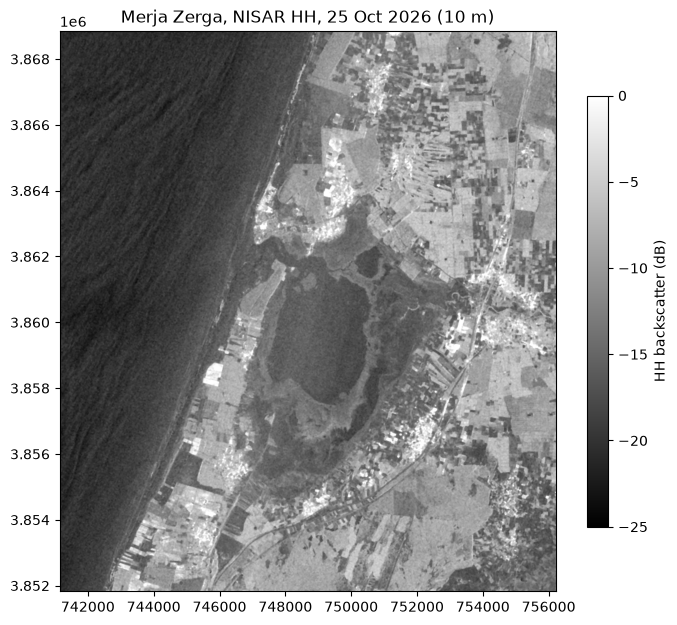

In [1]:
import glob, json, os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pyproj import Transformer
from scipy.ndimage import median_filter

# Merja Zerga lagoon (lon_min, lat_min, lon_max, lat_max)
BBOX = (-6.36, 34.78, -6.20, 34.93)
files = sorted(glob.glob("../data/raw/merja_zerga/*.h5"))   # 25 Oct first, 6 Nov second (when downloaded)
print("Files found:", [p.split("/")[-1][:60] for p in files])

def read_crop(path, bbox, pol="HHHH"):
    """Read only the bbox area from a NISAR GCOV file (frequency A). Returns dB image + coordinates."""
    with h5py.File(path, "r") as nisar:
        grid = nisar["science/LSAR/GCOV/grids/frequencyA"]
        x = grid["xCoordinates"][:]
        y = grid["yCoordinates"][:]
        epsg = int(grid["projection"].attrs["epsg_code"])
        to_map = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True)
        lon_min, lat_min, lon_max, lat_max = bbox
        xs, ys = to_map.transform([lon_min, lon_max, lon_min, lon_max], [lat_min, lat_min, lat_max, lat_max])
        cols = np.where((x >= min(xs)) & (x <= max(xs)))[0]
        rows = np.where((y >= min(ys)) & (y <= max(ys)))[0]
        power = grid[pol][rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]
    db = 10 * np.log10(np.where(power > 0, power, np.nan))
    return db, x[cols[0]:cols[-1] + 1], y[rows[0]:rows[-1] + 1], epsg

def despeckle(img_db, size=5):
    """Reduce radar speckle with a median filter. Empty pixels (NaN) stay empty."""
    empty = np.isnan(img_db)
    filled = np.where(empty, np.nanmedian(img_db), img_db)
    smooth = median_filter(filled, size=size)
    smooth[empty] = np.nan
    return smooth

# BEFORE = 25 Oct 2026 (end of the dry season)
before_db, crop_x, crop_y, epsg = read_crop(files[0], BBOX)
before_smooth = despeckle(before_db)
extent = [crop_x[0], crop_x[-1], crop_y[-1], crop_y[0]]
print("Crop size:", before_smooth.shape, "| pixel: 10 m | EPSG:", epsg)

plt.figure(figsize=(8, 8))
plt.imshow(before_smooth, cmap="gray", vmin=-25, vmax=0, extent=extent)
plt.colorbar(label="HH backscatter (dB)", shrink=0.7)
plt.title("Merja Zerga, NISAR HH, 25 Oct 2026 (10 m)")
plt.show()

Otsu: -13.29 dB | final threshold: -15.0 dB
Water/wet area on 25 Oct: 44.5 %


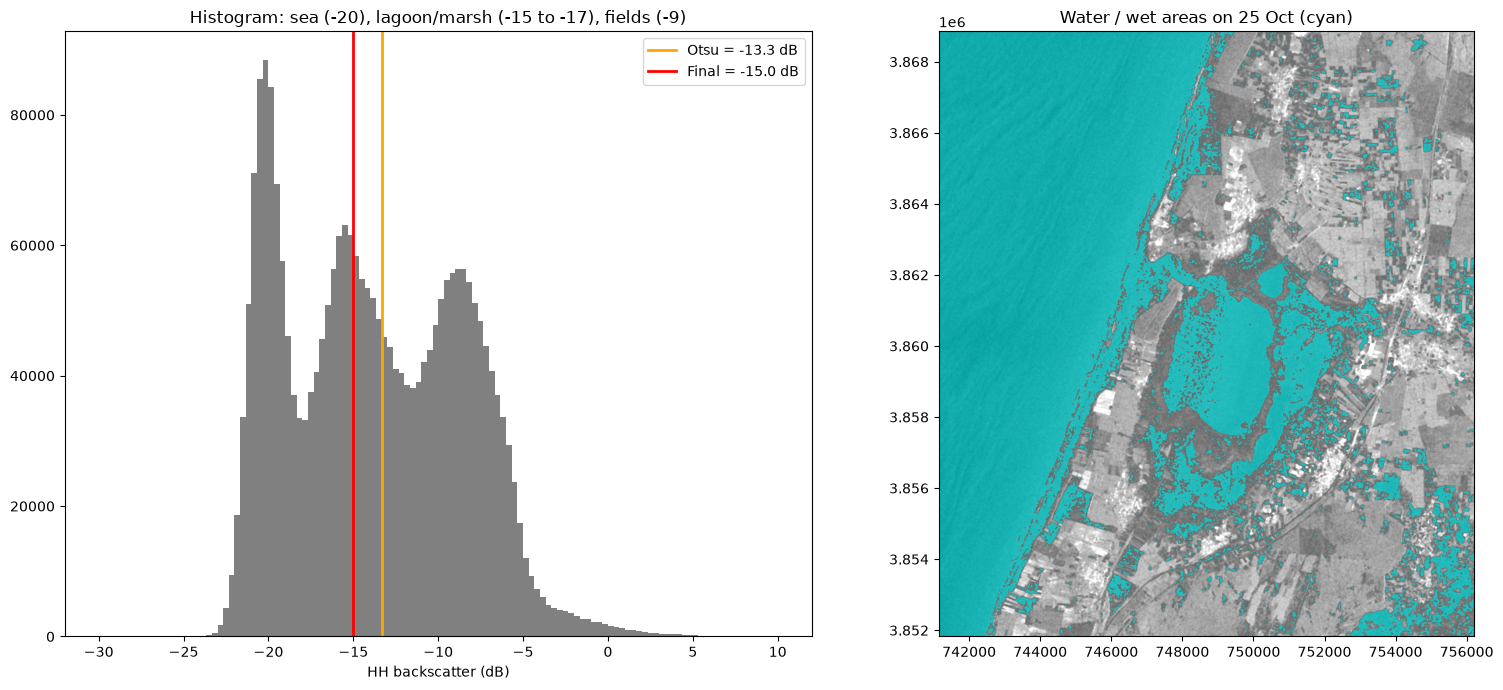

In [2]:
from skimage.filters import threshold_otsu

WATER_MAX_DB = -15.0   # physics guardrail: calm/shallow water in L-band HH is below about -15 dB

valid_pixels = before_smooth[np.isfinite(before_smooth)]
otsu = threshold_otsu(valid_pixels)
water_threshold = min(otsu, WATER_MAX_DB)
water_before = before_smooth < water_threshold

print("Otsu:", round(float(otsu), 2), "dB | final threshold:", water_threshold, "dB")
print("Water/wet area on 25 Oct:", round(float(np.nanmean(water_before) * 100), 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].hist(valid_pixels, bins=120, range=(-30, 10), color="gray")
axes[0].axvline(otsu, color="orange", linewidth=2, label=f"Otsu = {otsu:.1f} dB")
axes[0].axvline(water_threshold, color="red", linewidth=2, label=f"Final = {water_threshold:.1f} dB")
axes[0].set_xlabel("HH backscatter (dB)")
axes[0].set_title("Histogram: sea (-20), lagoon/marsh (-15 to -17), fields (-9)")
axes[0].legend()

axes[1].imshow(before_smooth, cmap="gray", vmin=-25, vmax=0, extent=extent)
axes[1].imshow(np.where(water_before, 1, np.nan), cmap="cool", alpha=0.6, extent=extent)
axes[1].set_title("Water / wet areas on 25 Oct (cyan)")
plt.tight_layout()
plt.show()

Multi-Otsu thresholds: [-17. -11.] dB
open water                  : 31.3 %
wet / low (lagoon, marsh)   : 34.8 %
land                        : 33.9 %


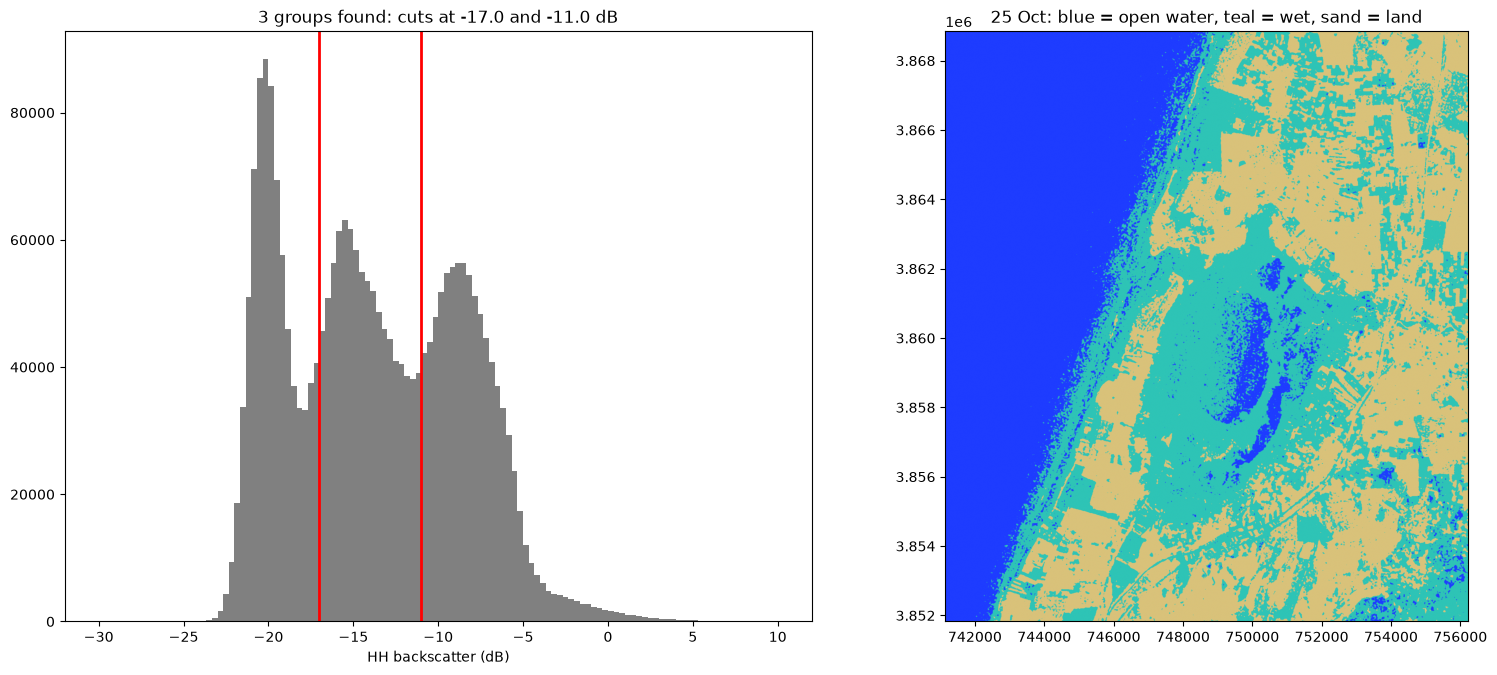

In [3]:
from skimage.filters import threshold_multiotsu
from matplotlib.colors import ListedColormap

# Multi-Otsu: find 2 thresholds -> 3 classes (open water / wet / land)
thresholds = threshold_multiotsu(before_smooth[np.isfinite(before_smooth)], classes=3)
print("Multi-Otsu thresholds:", np.round(thresholds, 1), "dB")

def classify(img_db, thresholds):
    """0 = open water, 1 = wet / low backscatter (lagoon, marsh), 2 = land. NaN stays NaN."""
    classes = np.digitize(img_db, thresholds).astype("float32")
    classes[np.isnan(img_db)] = np.nan
    return classes

classes_before = classify(before_smooth, thresholds)
names = ["open water", "wet / low (lagoon, marsh)", "land"]
for k, name in enumerate(names):
    print(f"{name:28s}: {np.nanmean(classes_before == k) * 100:.1f} %")

class_colors = ListedColormap(["#1e3cff", "#2ec4b6", "#d9c27a"])   # blue, teal, sand

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].hist(before_smooth[np.isfinite(before_smooth)], bins=120, range=(-30, 10), color="gray")
for t in thresholds:
    axes[0].axvline(t, color="red", linewidth=2)
axes[0].set_title(f"3 groups found: cuts at {thresholds[0]:.1f} and {thresholds[1]:.1f} dB")
axes[0].set_xlabel("HH backscatter (dB)")
S
axes[1].imshow(classes_before, cmap=class_colors, vmin=0, vmax=2, extent=extent)
axes[1].set_title("25 Oct: blue = open water, teal = wet, sand = land")
plt.tight_layout()
plt.show()

In [4]:
from PIL import Image
from rasterio.transform import from_origin
from rasterio.warp import calculate_default_transform, reproject, Resampling

OUT_DIR = "../public/data/merja_zerga"
os.makedirs(OUT_DIR, exist_ok=True)

def reproject_to_latlon(img, x, y, epsg, resampling=Resampling.bilinear):
    """Reproject a UTM image (pixel centers x, y) to lat/lon. Returns image + (south, west, north, east)."""
    pixel = abs(x[1] - x[0])
    height, width = img.shape
    left, top = x[0] - pixel / 2, y[0] + pixel / 2
    right, bottom = left + width * pixel, top - height * pixel
    src_transform = from_origin(left, top, pixel, pixel)
    dst_transform, dst_width, dst_height = calculate_default_transform(
        f"EPSG:{epsg}", "EPSG:4326", width, height, left, bottom, right, top)
    out = np.full((dst_height, dst_width), np.nan, dtype="float32")
    reproject(source=img.astype("float32"), destination=out,
              src_transform=src_transform, src_crs=f"EPSG:{epsg}",
              dst_transform=dst_transform, dst_crs="EPSG:4326",
              src_nodata=np.nan, dst_nodata=np.nan, resampling=resampling)
    west, north = dst_transform * (0, 0)
    east, south = dst_transform * (dst_width, dst_height)
    return out, (south, west, north, east)

def gray_rgba(img_db, vmin=-25, vmax=0):
    """Radar image -> grayscale RGBA, empty pixels transparent."""
    scaled = np.clip((img_db - vmin) / (vmax - vmin), 0, 1)
    gray = (np.nan_to_num(scaled) * 255).astype("uint8")
    alpha = np.where(np.isnan(img_db), 0, 255).astype("uint8")
    return np.dstack([gray, gray, gray, alpha])S

CLASS_RGBA = {0: (30, 60, 255, 220), 1: (46, 196, 182, 200), 2: (0, 0, 0, 0)}   # land = transparent

def classes_rgba(classes):
    rgba = np.zeros(classes.shape + (4,), dtype="uint8")
    for value, color in CLASS_RGBA.items():
        rgba[classes == value] = color
    return rgba

# Export BEFORE now (AFTER comes when the 6 Nov file is downloaded)
before_ll, bounds = reproject_to_latlon(before_smooth, crop_x, crop_y, epsg)
classes_before_ll, _ = reproject_to_latlon(classes_before, crop_x, crop_y, epsg, resampling=Resampling.nearest)

Image.fromarray(gray_rgba(before_ll)).save(f"{OUT_DIR}/before.png")
Image.fromarray(classes_rgba(classes_before_ll)).save(f"{OUT_DIR}/classes_before.png")

print("Saved before.png and classes_before.png")
print("Bounds (south, west, north, east):", [round(v, 4) for v in bounds])

Saved before.png and classes_before.png
Bounds (south, west, north, east): [34.7764, -6.3648, 34.9336, -6.1949]


Files: ['20261025', '20261106']
open water                  :  31.3 % ->  28.6 %
wet / low (lagoon, marsh)   :  34.8 % ->  32.1 %
land                        :  33.9 % ->  39.3 %
Became darker  : 1.05 %
Became brighter: 9.08 %
Median change  : 0.8 dB


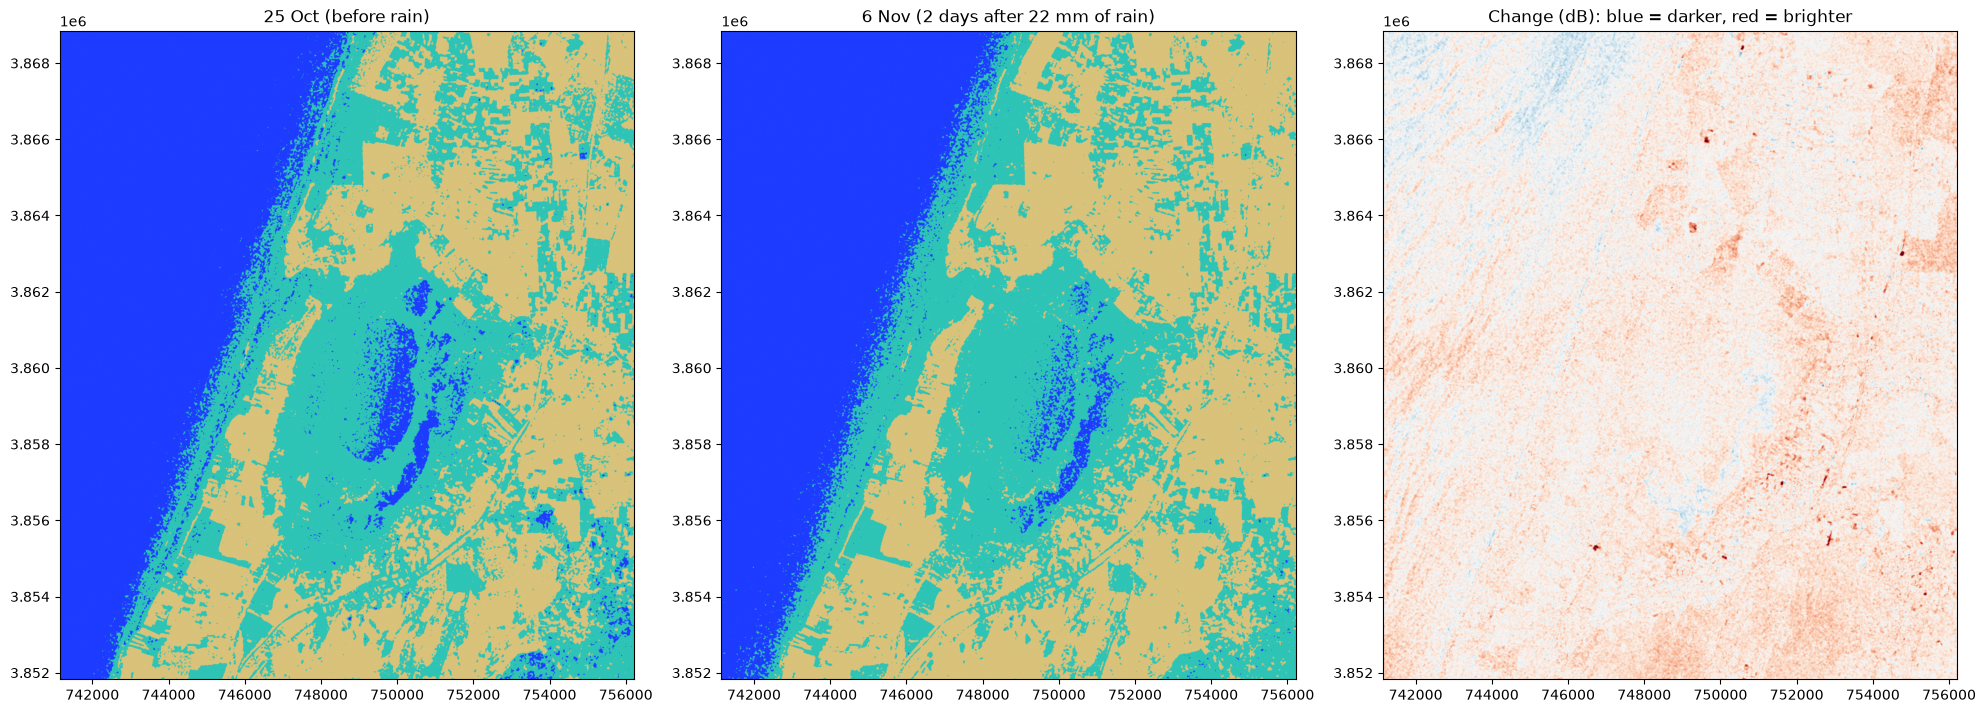

Saved after.png, change.png, classes_after.png, water.png


In [5]:
from matplotlib import colormaps

# Re-scan the folder: now there are 2 files (25 Oct, 6 Nov)
files = sorted(glob.glob("../data/raw/merja_zerga/*.h5"))
print("Files:", [p.split("_")[-6][:8] for p in files])

# AFTER = 6 Nov 2026 (2 days after 22 mm of rain), same thresholds as BEFORE = fair comparison
after_db, _, _, _ = read_crop(files[1], BBOX)
after_smooth = despeckle(after_db)
classes_after = classify(after_smooth, thresholds)

both_valid = np.isfinite(classes_before) & np.isfinite(classes_after)
diff_smooth = after_smooth - before_smooth

# Transition: 1 = became darker (moved to a more water-like class), 2 = became brighter
transition = np.full(classes_before.shape, np.nan, dtype="float32")
transition[both_valid] = 0
transition[both_valid & (classes_after < classes_before)] = 1
transition[both_valid & (classes_after > classes_before)] = 2

n = both_valid.sum()
for k, name in enumerate(names):
    print(f"{name:28s}: {np.mean(classes_before[both_valid] == k) * 100:5.1f} % -> {np.mean(classes_after[both_valid] == k) * 100:5.1f} %")
print("Became darker  :", round(float((transition == 1).sum() / n * 100), 2), "%")
print("Became brighter:", round(float((transition == 2).sum() / n * 100), 2), "%")
print("Median change  :", round(float(np.nanmedian(diff_smooth)), 2), "dB")

fig, axes = plt.subplots(1, 3, figsize=(20, 7))
axes[0].imshow(classes_before, cmap=class_colors, vmin=0, vmax=2, extent=extent)
axes[0].set_title("25 Oct (before rain)")
axes[1].imshow(classes_after, cmap=class_colors, vmin=0, vmax=2, extent=extent)
axes[1].set_title("6 Nov (2 days after 22 mm of rain)")
axes[2].imshow(diff_smooth, cmap="RdBu_r", vmin=-10, vmax=10, extent=extent)
axes[2].set_title("Change (dB): blue = darker, red = brighter")
plt.tight_layout()
plt.show()

# Export AFTER layers (same lat/lon grid as before.png)
TRANSITION_RGBA = {1: (30, 120, 255, 220), 2: (255, 165, 0, 220)}   # blue = darker, orange = brighter

def transition_rgba(t):
    rgba = np.zeros(t.shape + (4,), dtype="uint8")
    for value, color in TRANSITION_RGBA.items():
        rgba[t == value] = color
    return rgba

def colormap_rgba(img, cmap_name, vmin, vmax):
    scaled = np.clip((img - vmin) / (vmax - vmin), 0, 1)
    rgba = (colormaps[cmap_name](np.nan_to_num(scaled)) * 255).astype("uint8")
    rgba[..., 3] = np.where(np.isnan(img), 0, 255)
    return rgba

after_ll, _ = reproject_to_latlon(after_smooth, crop_x, crop_y, epsg)
change_ll, _ = reproject_to_latlon(diff_smooth, crop_x, crop_y, epsg)
classes_after_ll, _ = reproject_to_latlon(classes_after, crop_x, crop_y, epsg, resampling=Resampling.nearest)
transition_ll, _ = reproject_to_latlon(transition, crop_x, crop_y, epsg, resampling=Resampling.nearest)

Image.fromarray(gray_rgba(after_ll)).save(f"{OUT_DIR}/after.png")
Image.fromarray(colormap_rgba(change_ll, "RdBu_r", -10, 10)).save(f"{OUT_DIR}/change.png")
Image.fromarray(classes_rgba(classes_after_ll)).save(f"{OUT_DIR}/classes_after.png")
Image.fromarray(transition_rgba(transition_ll)).save(f"{OUT_DIR}/water.png")
print("Saved after.png, change.png, classes_after.png, water.png")

In [6]:
import math, warnings, requests
from scipy.ndimage import label, binary_opening

def read_text(dataset):
    value = dataset[()]
    return value.decode() if isinstance(value, bytes) else value

def scene_info(path, role):
    """Identity card of one NISAR scene, read from the file itself."""
    with h5py.File(path, "r") as nisar:
        ident = nisar["science/LSAR/identification"]
        return {"role": role, "granule": path.split("/")[-1].replace(".h5", ""),
                "datetime_utc": read_text(ident["zeroDopplerStartTime"])[:19] + "Z",
                "track": int(read_text(ident["trackNumber"])), "frame": int(read_text(ident["frameNumber"])),
                "direction": read_text(ident["orbitPassDirection"]), "polarization": "HH",
                "product": "NISAR L2 GCOV, L-band, frequency A (10 m)"}

def distance_m(lat1, lon1, lat2, lon2):
    r = 6371008.8
    p1, p2 = math.radians(lat1), math.radians(lat2)
    a = math.sin((p2 - p1) / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(math.radians(lon2 - lon1) / 2) ** 2
    return 2 * r * math.asin(math.sqrt(a))

to_map = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True)
to_latlon = Transformer.from_crs(f"EPSG:{epsg}", "EPSG:4326", always_xy=True)

# 1. Target = open-water core of the lagoon: biggest open-water blob that is NOT the sea
open_water = binary_opening(classes_before == 0, iterations=2)
labels, _ = label(open_water)
sizes = np.bincount(labels.ravel())
sizes[0] = 0
sea, lagoon_core = np.argsort(sizes)[::-1][:2]        # 1st = sea, 2nd = lagoon core
rows, cols = np.where(labels == lagoon_core)
target_lon, target_lat = to_latlon.transform(crop_x[cols].mean(), crop_y[rows].mean())
edge_lon, edge_lat = to_latlon.transform(crop_x[cols], crop_y[rows])
farthest_m = max(distance_m(target_lat, target_lon, la, lo) for la, lo in zip(edge_lat[::50], edge_lon[::50]))
answer_target = {"label": "Merja Zerga lagoon open-water core",
                 "lat": round(float(target_lat), 5), "lng": round(float(target_lon), 5),
                 "toleranceMeters": int(round(farthest_m + 500, -2)),
                 "precisionRadiusMeters": int(round(math.sqrt(sizes[lagoon_core] * 100 / math.pi), -1))}

# 2. Weather between the two dates (Open-Meteo, daily rain)
w = requests.get("https://archive-api.open-meteo.com/v1/archive", timeout=30, params={
    "latitude": 34.8667, "longitude": -6.2833, "start_date": "2026-10-20", "end_date": "2026-11-07",
    "daily": "precipitation_sum", "timezone": "Africa/Casablanca"}).json()["daily"]
daily_rain = {d: round(p or 0, 1) for d, p in zip(w["time"], w["precipitation_sum"])}
rain_between = round(sum(v for d, v in daily_rain.items() if "2026-10-25" < d <= "2026-11-06"), 1)
with open(f"{OUT_DIR}/weather.json", "w") as f:
    json.dump({"zone": "merja_zerga", "latitude": 34.8667, "longitude": -6.2833, "source": "Open-Meteo Historical Weather API",
               "daily_precipitation_mm": daily_rain, "rain_between_scenes_mm": rain_between}, f, indent=1)

# 3. metadata.json (same structure as Valencia)
before_scene, after_scene = scene_info(files[0], "before"), scene_info(files[1], "after")
south, west, north, east = bounds
def pct(mask):
    return round(float(mask.sum() / both_valid.sum() * 100), 2)
metadata = {
    "zone": "merja_zerga", "name": "Merja Zerga lagoon, Morocco", "label": "real NISAR data",
    "bounds": [[round(south, 6), round(west, 6)], [round(north, 6), round(east, 6)]], "crs": "EPSG:4326",
    "scenes": [before_scene, after_scene],
    "layers": {
        "before": {"file": "before.png", "description": "HH backscatter, BEFORE", "range_db": [-25, 0]},
        "after": {"file": "after.png", "description": "HH backscatter, AFTER", "range_db": [-25, 0]},
        "change": {"file": "change.png", "description": "AFTER - BEFORE (blue = darker, red = brighter)", "range_db": [-10, 10]},
        "water": {"file": "water.png", "description": "Class change (Multi-Otsu)",
                  "legend": {"became_darker": "#1e78ff", "became_brighter": "#ffa500"}},
        "classes_before": {"file": "classes_before.png", "legend": {"open_water": "#1e3cff", "wet_low": "#2ec4b6"}},
        "classes_after": {"file": "classes_after.png", "legend": {"open_water": "#1e3cff", "wet_low": "#2ec4b6"}},
    },
    "processing": {"speckle_filter": "median 5x5", "method": "Multi-Otsu, 3 classes (open water / wet-low / land)",
                   "thresholds_db": [round(float(t), 1) for t in thresholds]},
    "results": {"became_darker_pct": pct(transition == 1), "became_brighter_pct": pct(transition == 2),
                "median_change_db": round(float(np.nanmedian(diff_smooth)), 2), "rain_between_scenes_mm": rain_between,
                "conclusion": "After the first autumn rain, soils became brighter (wet soil reflects more), "
                              "while the lagoon keeps its open-water core."},
    "source": "NISAR data courtesy of NASA/JPL-Caltech and ISRO, distributed by ASF DAAC.",
    "weather_source": "Open-Meteo Historical Weather API",
}
with open(f"{OUT_DIR}/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# 4. grid.json for SARah (10 m -> 80 m, median of 8x8 blocks)
def block_median(img, factor):
    r, c = img.shape[0] // factor * factor, img.shape[1] // factor * factor
    blocks = img[:r, :c].reshape(r // factor, factor, c // factor, factor)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        return np.nanmedian(blocks, axis=(1, 3)), r, c
FACTOR = 8
before_grid, used_r, used_c = block_median(before_ll, FACTOR)
after_grid, _, _ = block_median(after_ll, FACTOR)
lat_step, lon_step = (north - south) / before_ll.shape[0], (east - west) / before_ll.shape[1]
def to_list(a):
    return [[None if np.isnan(v) else round(float(v), 1) for v in row] for row in a]
with open(f"{OUT_DIR}/grid.json", "w") as f:
    json.dump({"zone": "merja_zerga", "label": "real NISAR data",
               "bounds": [[round(north - used_r * lat_step, 6), round(west, 6)], [round(north, 6), round(west + used_c * lon_step, 6)]],
               "shape": list(before_grid.shape), "cell_size_m": 10 * FACTOR, "row_order": "north_to_south",
               "thresholds_db": [round(float(t), 1) for t in thresholds],
               "before_db": to_list(before_grid), "after_db": to_list(after_grid)}, f, separators=(",", ":"))

# 5. level_fields.json (public) + answer_target.json (private) for the backend
level_fields = {
    "targetLocation": "Merja Zerga lagoon, Moulay Bousselham, Morocco",
    "regionCenter": [round((south + north) / 2, 4), round((west + east) / 2, 4)], "defaultZoom": 12,
    "boundingBox": {"north": round(north, 4), "south": round(south, 4), "east": round(east, 4), "west": round(west, 4)},
    "satellite": {"mission": "NISAR (NASA-ISRO SAR)", "sensor": "L-SAR, GCOV frequency A (40 MHz)", "frequencyGhz": 1.25,
                  "wavelengthCm": 24.0, "polarization": "Dual-Pol (HH + HV)", "passDirection": before_scene["direction"],
                  "lookAngleDeg": None, "acquisitionDate": before_scene["datetime_utc"], "repeatPassDays": 12,
                  "groundResolutionM": 10.0},
    "dataProducts": [f"NISAR L2 GCOV HH, {before_scene['datetime_utc'][:10]} (track {before_scene['track']}, {before_scene['direction']})",
                     f"NISAR L2 GCOV HH, {after_scene['datetime_utc'][:10]} (track {after_scene['track']}, {after_scene['direction']})",
                     "Multi-Otsu classes (open water / wet-low / land) and change map",
                     f"Open-Meteo daily precipitation ({rain_between} mm between the two dates)"],
}
with h5py.File(files[0], "r") as nisar:
    cube = nisar["science/LSAR/GCOV/metadata/radarGrid"]
    heights, cx, cy = cube["heightAboveEllipsoid"][:], cube["xCoordinates"][:], cube["yCoordinates"][:]
    tx, ty = to_map.transform(target_lon, target_lat)
    level_fields["satellite"]["lookAngleDeg"] = round(float(cube["incidenceAngle"][int(np.argmin(abs(heights - 50))),
                                                     int(np.argmin(abs(cy - ty))), int(np.argmin(abs(cx - tx)))]), 1)
with open(f"{OUT_DIR}/level_fields.json", "w") as f:
    json.dump(level_fields, f, indent=2)
os.makedirs("../server-data/merja_zerga", exist_ok=True)
with open("../server-data/merja_zerga/answer_target.json", "w") as f:
    json.dump(answer_target, f, indent=2)

print("Rain between scenes:", rain_between, "mm")
print("PRIVATE answer_target:", answer_target)
print("Look angle:", level_fields["satellite"]["lookAngleDeg"], "deg")S
print("Files:", sorted(os.listdir(OUT_DIR)))

Rain between scenes: 25.0 mm
PRIVATE answer_target: {'label': 'Merja Zerga lagoon open-water core', 'lat': 34.8432, 'lng': -6.26617, 'toleranceMeters': 2200, 'precisionRadiusMeters': 710}
Look angle: 45.7 deg
Files: ['after.png', 'before.png', 'change.png', 'classes_after.png', 'classes_before.png', 'grid.json', 'level_fields.json', 'metadata.json', 'water.png', 'weather.json']
